In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import os
from astropy.table import Table
from astropy.io import fits
import astropy.units as u
from bcutil import bcstar
from numpy.random import normal,rand


Loading in the Gaia DR3 data, alongside stellar parameters for all literature stars

In [3]:
# Loading in the literature Gaia DR3 data
lit_gaia_df = pd.read_csv('/data/misfit/benlowe/xshooter/lit_abund_data/all_lit_gaiadr3_final.csv')

# Loading in the ebv data, then merging with the gaia data
ebv_df = pd.read_csv('/data/misfit/benlowe/xshooter/lit_abund_data/all_lit_ebv.csv')
lit_gaia_df = lit_gaia_df.merge(ebv_df[['source_id', 'ebv_corr']], on='source_id', how='left')
lit_gaia_df.drop_duplicates(subset=['source_id'], inplace=True)
lit_gaia_df['star_id'] = lit_gaia_df['star_id'].str.strip()
display(lit_gaia_df)

# Loading in the rv data
lit_rv_df = pd.read_csv('/data/misfit/benlowe/xshooter/lit_abund_data/all_lit_rvs.csv')
lit_rv_df['star_id'] = lit_rv_df['star_id'].str.strip()

,catalog,star_id,source_id,random_index,ra,dec,parallax,parallax_error,parallax_over_error,pmra,...,target_id,target_ra,target_dec,target_parallax,target_pm_ra,target_pm_dec,target_radial_velocity,epoch,target_separation (deg),ebv_corr
0,yong2013,52972-1213-507,811812182598263552,730540375,139.707938,37.740593,0.468856,0.039756,11.793310,-5.860822,...,Gaia DR3 811812182598263552,139.707938,37.740593,0.4689,-5.8608,-33.2725,0.0000,2016.0,0.000000e+00,0.233259
1,yong2013,53327-2044-515,290930261314166528,1215239180,25.150925,23.749406,1.066217,0.036955,28.851522,0.972496,...,Gaia DR3 290930261314166528,25.150925,23.749406,1.0662,0.9725,-21.5905,0.0000,2016.0,0.000000e+00,0.039034
2,yong2013,54142-2667-094,598558225898219776,772626430,132.902825,10.300841,0.422213,0.028656,14.734057,-8.773143,...,Gaia DR3 598558225898219776,132.902825,10.300841,0.4222,-8.7731,-17.1661,0.0000,2016.0,1.776357e-15,0.006169
3,yong2013,BS 16545-089,760839819965612928,344569189,171.114717,36.841186,0.644339,0.023748,27.132257,10.309770,...,Gaia DR3 760839819965612928,171.114717,36.841186,0.6443,10.3098,-34.1174,0.0000,2016.0,0.000000e+00,0.222606
4,yong2013,CS 30336-049,6795730493933072128,60677280,311.348047,-28.710012,0.062969,0.017374,3.624422,-1.727017,...,Gaia DR3 6795730493933072128,311.348047,-28.710012,0.0630,-1.7270,-8.1800,-235.8673,2016.0,0.000000e+00,0.014142
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
316,yong2021,J224145.62-064643.0,2623363791014198656,990092424,340.440108,-6.778676,0.075457,0.018667,4.042358,1.869163,...,Gaia DR3 2623363791014198656,340.440108,-6.778676,0.0755,1.8692,-2.8984,-207.4769,2016.0,8.881784e-16,0.047824
317,yong2021,J230525.31-213807.0,2398202677437168384,779426047,346.355546,-21.635311,0.286466,0.012346,23.202960,-1.075391,...,Gaia DR3 2398202677437168384,346.355546,-21.635311,0.2865,-1.0754,-15.1677,-17.3665,2016.0,0.000000e+00,0.060906
318,yong2021,J230702.22-693718.5,6384594749521894400,286939962,346.759342,-69.621844,0.052283,0.015166,3.447462,1.060945,...,Gaia DR3 6384594749521894400,346.759342,-69.621844,0.0523,1.0609,-5.9018,153.2275,2016.0,0.000000e+00,0.254270
319,yong2021,J232121.57-160505.4,2406023396270909440,605784975,350.339926,-16.084881,0.456265,0.013901,32.823170,17.221111,...,Gaia DR3 2406023396270909440,350.339926,-16.084881,0.4563,17.2211,3.4440,-40.4604,2016.0,0.000000e+00,0.080765


In [5]:
# Loading in the stellar parameters for the literature stars
yong2013_params = Table.read('/data/misfit/benlowe/xshooter/lit_abund_data/yong2013_data.fit')
yong2013_params = yong2013_params[['Name', 'Teff', 'log_g_', 'Fe_H']].to_pandas()
yong2013_params = yong2013_params.rename(columns={'Name':'star_id', 'Teff':'teff', 'log_g_':'logg', 'Fe_H':'feh'})
yong2013_params['star_id'] = yong2013_params['star_id'].str.decode('utf-8').str.strip()  # Decode bytes to string

jacobson2015_params = Table.read('/data/misfit/benlowe/xshooter/lit_abund_data/jacobson2015_params.fit')
jacobson2015_params = jacobson2015_params[['ID', 'Teff', 'log_g_L', '__Fe_H_L']].to_pandas()
jacobson2015_params = jacobson2015_params.rename(columns={'ID':'star_id', 'Teff':'teff', 'log_g_L':'logg', '__Fe_H_L':'feh'})
jacobson2015_params['star_id'] = jacobson2015_params['star_id'].str.decode('utf-8').str.strip()  # Decode bytes to string

marino2019_params = Table.read('/data/misfit/benlowe/xshooter/lit_abund_data/marino2019_params.fit')
marino2019_params = marino2019_params[['Name', 'Teff', 'logg', '__Fe_H_LTE']].to_pandas()
marino2019_params = marino2019_params.rename(columns={'Name':'star_id', 'Teff':'teff', 'logg':'logg', '__Fe_H_LTE':'feh'})
marino2019_params['star_id'] = marino2019_params['star_id'].str.decode('utf-8').str.strip()  # Decode bytes to string

yong2021_params = Table.read('/data/misfit/benlowe/xshooter/lit_abund_data/yong2021_params.fit')
yong2021_params = yong2021_params[['SMSS', 'Teff', 'logg', '__Fe_H_']].to_pandas()
yong2021_params = yong2021_params.rename(columns={'SMSS':'star_id', 'Teff':'teff', 'logg':'logg', '__Fe_H_':'feh'})
yong2021_params['star_id'] = yong2021_params['star_id'].str.decode('utf-8').str.strip()  # Decode bytes to string


# Combining all stellar parameters into one dataframe
params_df = pd.concat([yong2013_params, jacobson2015_params, marino2019_params, yong2021_params], ignore_index=True)


# Merging the stellar parameters with the radial velocity data
comb_df = lit_rv_df.merge(params_df, on='star_id', how='left')
comb_df.drop_duplicates(subset=['star_id'], inplace=True)

# Merging the combined dataframe with the Gaia data (parallax, magnitude)
comb_df = comb_df[['star_id', 'rv', 'rv_err', 'teff', 'logg', 'feh']].merge(lit_gaia_df, on='star_id', how='left')

# Saving the final dataframe to a csv file
comb_df.to_csv('/data/misfit/benlowe/xshooter/lit_abund_data/all_lit_combined_data.csv', index=False)
comb_df

,star_id,rv,rv_err,teff,logg,feh,catalog,source_id,random_index,ra,...,target_id,target_ra,target_dec,target_parallax,target_pm_ra,target_pm_dec,target_radial_velocity,epoch,target_separation (deg),ebv_corr
0,52972-1213-507,-176.950000,0.5,6463,4.34,-2.98,yong2013,8.118122e+17,7.305404e+08,139.707938,...,Gaia DR3 811812182598263552,139.707938,37.740593,0.4689,-5.8608,-33.2725,0.0000,2016.0,0.000000e+00,0.233259
1,53327-2044-515,-193.500000,0.5,5703,4.68,-4.00,yong2013,2.909303e+17,1.215239e+09,25.150925,...,Gaia DR3 290930261314166528,25.150925,23.749406,1.0662,0.9725,-21.5905,0.0000,2016.0,0.000000e+00,0.039034
2,54142-2667-094,43.400000,0.7,6456,3.87,-2.96,yong2013,5.985582e+17,7.726264e+08,132.902825,...,Gaia DR3 598558225898219776,132.902825,10.300841,0.4222,-8.7731,-17.1661,0.0000,2016.0,1.776357e-15,0.006169
3,BS 16545-089,-161.166667,0.5,6486,3.82,-3.44,yong2013,7.608398e+17,3.445692e+08,171.114717,...,Gaia DR3 760839819965612928,171.114717,36.841186,0.6443,10.3098,-34.1174,0.0000,2016.0,0.000000e+00,0.222606
4,CS 30336-049,-236.633333,0.8,4725,1.19,-4.10,yong2013,6.795730e+18,6.067728e+07,311.348047,...,Gaia DR3 6795730493933072128,311.348047,-28.710012,0.0630,-1.7270,-8.1800,-235.8673,2016.0,0.000000e+00,0.014142
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
310,J224145.62-064643.0,-201.600000,0.5,4800,1.46,-3.19,yong2021,2.623364e+18,9.900924e+08,340.440108,...,Gaia DR3 2623363791014198656,340.440108,-6.778676,0.0755,1.8692,-2.8984,-207.4769,2016.0,8.881784e-16,0.047824
311,J230525.31-213807.0,-15.700000,0.5,5100,2.26,-3.35,yong2021,2.398203e+18,7.794260e+08,346.355546,...,Gaia DR3 2398202677437168384,346.355546,-21.635311,0.2865,-1.0754,-15.1677,-17.3665,2016.0,0.000000e+00,0.060906
312,J230702.22-693718.5,173.900000,0.5,4850,1.61,-2.89,yong2021,6.384595e+18,2.869400e+08,346.759342,...,Gaia DR3 6384594749521894400,346.759342,-69.621844,0.0523,1.0609,-5.9018,153.2275,2016.0,0.000000e+00,0.254270
313,J232121.57-160505.4,-39.100000,0.5,5450,3.23,-3.03,yong2021,2.406023e+18,6.057850e+08,350.339926,...,Gaia DR3 2406023396270909440,350.339926,-16.084881,0.4563,17.2211,3.4440,-40.4604,2016.0,0.000000e+00,0.080765


In [6]:
# Identifying parallax quality
good = []
bad = []
for i, row in comb_df.iterrows():
    star = row['source_id']
    plx = row['parallax']
    plx_err = row['parallax_error']
    if plx > 3 * plx_err:
        good.append(star)
    elif plx <= 3 * plx_err:
        bad.append(star)
        # print(plx/plx_err)

print("Stars with good parallax measurements vs. bad:")
print(f"Good: {len(good)} ({len(good)/len(comb_df)*100:.2f}%)")
print(f"Bad: {len(bad)} ({len(bad)/len(comb_df)*100:.2f}%)")

Stars with good parallax measurements vs. bad:
Good: 263 (83.49%)
Bad: 49 (15.56%)


Determining the mean and standard deviation of the distances from the derived values

In [14]:
folder

'/data/misfit/benlowe/xshooter/lit_abund_data/distances/yong2021/'

In [18]:
# Getting the list of folders
path = '/data/misfit/benlowe/xshooter/lit_abund_data/distances/'
lit_folders = [path + f + '/' for f in os.listdir(path) if os.path.isdir(os.path.join(path, f))]

# Looping through the folders and reading in the distance data
dist_dfs = []
for folder in lit_folders:
    stars_list = [folder + s for s in os.listdir(folder) if s.endswith('.csv')]
    
    # Looping through the star files in each folder and reading in the distance data
    for star_file in stars_list:
        star_df = pd.read_csv(star_file)
        star_id = str(os.path.basename(star_file).split('_dists.csv')[0])
        catalog = folder.split('/')[-2]
        
        # Calculating the mean and std of the distance samples
        star_dist_mean = star_df['dist'].mean()
        star_dist_std = star_df['dist'].std()
        
        # Storing the results in a dictionary
        star_dict = {
            'star_id': star_id,
            'catalog': catalog,
            'dist_mean': star_dist_mean,
            'dist_std': star_dist_std
        }
        dist_dfs.append(star_dict)

# Combining all the distance data into a single dataframe
dist_df = pd.DataFrame(dist_dfs)
dist_df.to_csv('/data/misfit/benlowe/xshooter/lit_abund_data/distances/all_dist_res.csv', index=False)
        
        

Calculating the distances to these stars via MCMC

**DO THIS IN THE CALC_DIST.PY FILE**

Code below used for TESTING

In [ ]:
def dist_plx(plx):
    """Calculates distance and distance error from parallax and parallax error.
    
    Parameters
    ----------
    plx (float): 
        Parallax in mas.
    plx_err (float): 
        Parallax error in mas.
        
    Returns
    -------
    dist (float):
        Distance in kpc.
    dist_err (float):
        Distance error in kpc.
    """

    # Calculating the distance in kpc
    dist = 1/plx  
    
    return dist


def dist_absMag(star_id, teff, logg, feh, ebv, m_g):
    """Calculates the distance using the distance modulus. This requires the absolute
    magnitude to be calculated first, done using the stefan-boltzman law mixed with 
    various canonical equations. Bolometric corrections are calculated using the
    bcutil package.
    
    Parameters
    ----------
    star_id (str):
        Star identifier.
    teff (float): 
        Effective temperature in K.
    logg (float): 
        Log surface gravity in dex.
    feh (float): 
        Metallicity in dex.
    ebv (float): 
        E(B-V) value for extinction correction.
    m_g (float): 
        Apparent Gaia G magnitude.
        
    Returns
    -------
    dist (float):
        Distance in kpc.
    """
    
    def calc_absM(teff, logg, bc):
        """Calculates the absolute Gaia G magnitude and its error.
        
        Parameters
        ----------
        teff (float): 
            Effective temperature in K.
        logg (float): 
            Log surface gravity in dex.
        bc (float): 
            Bolometric correction.
        
        Returns
        -------
        M_G (float):
            Absolute Gaia G magnitude.
        M_G_err (float):
            Absolute Gaia G magnitude error.
        """
        
        # Solar values
        logg_sol = 4.438
        mass_sol = 1
        teff_sol = 5771
        M_sol = 4.75
        
        # Assumptions made on the star
        mass = 0.8
        
        # Calculating the absolute bolometric magnitude
        M = 5/2 * (logg-logg_sol-np.log10((mass*teff**4)/(mass_sol*teff_sol**4))) + M_sol
        
        # Using the bolometric correction to get the absolute gaia magnitude
        M_G = M - bc
        
        return M_G
    
    
    # Calculating the bolometric correction
    bc = bcstar(sid=star_id, 
                teff=teff, 
                logg=logg, 
                feh=feh,
                ebv=ebv, 
                filters='G3', retarr=True, Rv=3.1)
    bc_val = bc[0][0]
    

    # Calculating the absolute magnitude and its error
    M_G = calc_absM(teff=teff,
                    logg=logg,
                    bc=bc_val)
    
    
    # Calculating the distance from the apparent and absolute magnitudes
    dist = 10**((m_g-M_G+5)/5)
    dist = dist/1000  # Converting to kpc
    
    return dist

In [14]:
test = comb_df.iloc[[0]]
test

,star_id,rv,teff,logg,feh,catalog,source_id,random_index,ra,dec,...,target_id,target_ra,target_dec,target_parallax,target_pm_ra,target_pm_dec,target_radial_velocity,epoch,target_separation (deg),ebv_corr
0,52972-1213-507,-176.95,6463,4.34,-2.98,yong2013,8.118122e+17,730540375.0,139.707938,37.740593,...,Gaia DR3 811812182598263552,139.707938,37.740593,0.4689,-5.8608,-33.2725,0.0,2016.0,0.0,0.233259


In [27]:
def run_mcmc_dist(df):
    """Runs an MCMC to estimate distances (mean) and their errors (standard deviation) for a set of stars.
    Will use two different methods depending on the quality of the parallax measurement:
    - For stars with 'good' parallaxes (parallax > 3 * parallax_error), distances are derived from the parallax.
    - For stars with 'bad' parallaxes (parallax <= 3 * parallax_error), distances are derived from the absolute magnitude.
    
    Parameters
    ----------
    df (pandas.DataFrame):
        Dataframe containing the stellar parameters and Gaia data.
        
    Returns
    -------
    None
    """
     
    for i, entry in df.iterrows():
        
        # Extracting the stellar parameters
        star_id = entry['star_id']
        teff = entry['teff']
        teff_err = 100 # Assuming a constant error of 100 K
        
        logg = entry['logg']
        logg = 0.3  # Assuming a constant error of 0.3 dex
        
        feh = entry['feh']
        feh_err = 0.3 # Assuming a constant error of 0.3 dex
        
        ebv = entry['ebv_corr']
        env_err = 0.1 * float(ebv) # Taking error of reddening as 10%
        
        m_g = entry['phot_g_mean_mag']
        m_g_err = (2.5/np.log(10)) * 1/(float(entry['phot_g_mean_flux_over_error']))
        
        plx = entry['parallax']
        plx_err = entry['parallax_error']
        
        # Beginning MCMC calculation
        nrand = 100
        n_success = 0
        res_list = []
        print(f"Running star {star_id} ({i+1}/{len(df)})")
        
        while n_success < nrand:
            print(f"  Iteration {n_success+1}/{nrand}")
            # Randomising the input parameters based on their errors
            teff_rand = normal(loc=teff, scale=teff_err)
            logg_rand = normal(loc=logg, scale=logg)
            feh_rand = normal(loc=feh, scale=feh_err)
            m_g_rand = normal(loc=m_g, scale=m_g_err)
            plx_rand = normal(loc=plx, scale=plx_err)
            ebv_rand = normal(loc=ebv, scale=env_err)
            
            # Calculating distances based on their parallax quality
            # For stars with 'good' parallaxes, derive distance from parallax
            if plx_rand > 3 * plx_err:
                plx_sigma = plx_rand/plx_err
                plx_quality = 'good'
                
                dist_rand = dist_plx(plx=plx_rand)
                        
            # For stars with 'bad' parallaxes, derive distance from absolute magnitude
            elif plx_rand <= 3 * plx_err:
                plx_sigma = plx_rand/plx_err
                plx_quality = 'bad'      
                
                dist_rand = dist_absMag(star_id=star_id, 
                                        teff=teff_rand, 
                                        logg=logg_rand, 
                                        feh=feh_rand, 
                                        ebv=ebv_rand, 
                                        m_g=m_g_rand)
            
            # Only accepting physical distances, otherwise re-sample
            if dist_rand > 0:
                res_dict = {
                    'it': n_success+1,
                    'dist': dist_rand,
                    'plx_sigma': plx_sigma,
                    'plx_quality': plx_quality
                }
                n_success += 1
                res_list.append(res_dict)
            else:
                print("Unphysical distance, re-sampling...")
                continue
        
        # End of MCMC calculation
        res_df = pd.DataFrame(res_list)
        display(res_df)

        # Calculating the mean distance and its error
        dist_mean = res_df['dist'].mean()
        dist_std = res_df['dist'].std()
        print(f"Star {star_id}: Distance = {dist_mean:.3f} +/- {dist_std:.3f} kpc")
        
        return res_df
        
df = run_mcmc_dist(test)

        


Running star 52972-1213-507 (1/1)
  Iteration 1/100
  Iteration 2/100
  Iteration 3/100
  Iteration 4/100
  Iteration 5/100
  Iteration 6/100
  Iteration 7/100
  Iteration 8/100
  Iteration 9/100
  Iteration 10/100
  Iteration 11/100
  Iteration 12/100
  Iteration 13/100
  Iteration 14/100
  Iteration 15/100
  Iteration 16/100
  Iteration 17/100
  Iteration 18/100
  Iteration 19/100
  Iteration 20/100
  Iteration 21/100
  Iteration 22/100
  Iteration 23/100
  Iteration 24/100
  Iteration 25/100
  Iteration 26/100
  Iteration 27/100
  Iteration 28/100
  Iteration 29/100
  Iteration 30/100
  Iteration 31/100
  Iteration 32/100
  Iteration 33/100
  Iteration 34/100
  Iteration 35/100
  Iteration 36/100
  Iteration 37/100
  Iteration 38/100
  Iteration 39/100
  Iteration 40/100
  Iteration 41/100
  Iteration 42/100
  Iteration 43/100
  Iteration 44/100
  Iteration 45/100
  Iteration 46/100
  Iteration 47/100
  Iteration 48/100
  Iteration 49/100
  Iteration 50/100
  Iteration 51/100
  Iter

,it,dist,plx_sigma,plx_quality
0,1,2.362945,10.644932,good
1,2,2.309619,10.890709,good
2,3,2.067252,12.167550,good
3,4,1.877510,13.397205,good
4,5,1.928486,13.043075,good
...,...,...,...,...
95,96,2.245412,11.202127,good
96,97,2.265451,11.103037,good
97,98,1.906118,13.196131,good
98,99,2.163008,11.628894,good


Star 52972-1213-507: Distance = 2.151 +/- 0.152 kpc


In [47]:
import glob
el = '3.1'
files  = np.sort(glob.glob('grid/STcol*Rv'+el+'*.dat'))
files

array(['grid/STcolors_2MASS_GaiaDR2_EDR3_Rv3.1_EBV_0.00.dat',
       'grid/STcolors_2MASS_GaiaDR2_EDR3_Rv3.1_EBV_0.02.dat',
       'grid/STcolors_2MASS_GaiaDR2_EDR3_Rv3.1_EBV_0.04.dat',
       'grid/STcolors_2MASS_GaiaDR2_EDR3_Rv3.1_EBV_0.06.dat',
       'grid/STcolors_2MASS_GaiaDR2_EDR3_Rv3.1_EBV_0.08.dat',
       'grid/STcolors_2MASS_GaiaDR2_EDR3_Rv3.1_EBV_0.10.dat',
       'grid/STcolors_2MASS_GaiaDR2_EDR3_Rv3.1_EBV_0.12.dat',
       'grid/STcolors_2MASS_GaiaDR2_EDR3_Rv3.1_EBV_0.14.dat',
       'grid/STcolors_2MASS_GaiaDR2_EDR3_Rv3.1_EBV_0.16.dat',
       'grid/STcolors_2MASS_GaiaDR2_EDR3_Rv3.1_EBV_0.18.dat',
       'grid/STcolors_2MASS_GaiaDR2_EDR3_Rv3.1_EBV_0.20.dat',
       'grid/STcolors_2MASS_GaiaDR2_EDR3_Rv3.1_EBV_0.22.dat',
       'grid/STcolors_2MASS_GaiaDR2_EDR3_Rv3.1_EBV_0.24.dat',
       'grid/STcolors_2MASS_GaiaDR2_EDR3_Rv3.1_EBV_0.26.dat',
       'grid/STcolors_2MASS_GaiaDR2_EDR3_Rv3.1_EBV_0.28.dat',
       'grid/STcolors_2MASS_GaiaDR2_EDR3_Rv3.1_EBV_0.30.dat',
       '

(0.0, 14.7)

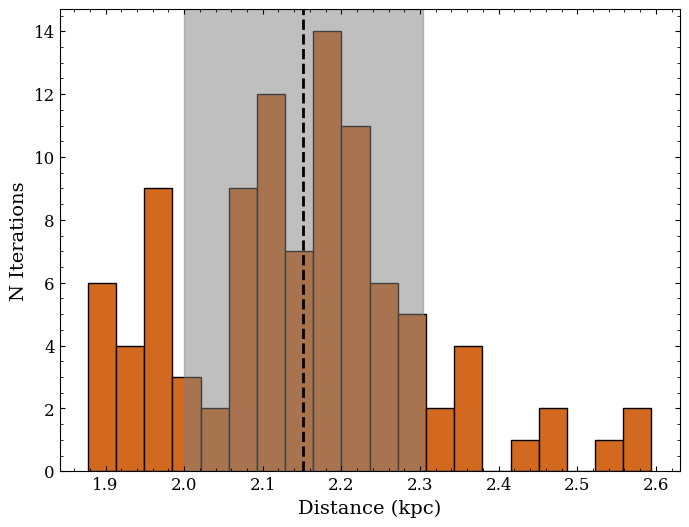

In [45]:
plt.figure(figsize=(8,6))
plt.hist(df['dist'], bins=20, color='chocolate', alpha=1, edgecolor='black')
ylims = plt.gca().get_ylim()

plt.axvline(df['dist'].mean(), color='black', linestyle='dashed', linewidth=2)
plt.fill_betweenx(y=ylims, x1=df['dist'].mean() - df['dist'].std(), x2=df['dist'].mean() + df['dist'].std(), color='gray', alpha=0.5)

plt.xlabel('Distance (kpc)')
plt.ylabel('N Iterations')
plt.ylim(ylims)